In [1]:
import numpy as np
import time
import matplotlib.pyplot as plt

import sys
import os
# This gets the absolute path to the 'EE675' folder
parent_folder = os.path.abspath(os.path.join(os.getcwd(), ".."))
# Add it to the system path if it's not already there
if parent_folder not in sys.path:
    sys.path.append(parent_folder)

from kernel import kernel
from reward import reward
from value_iteration import value_iteration
from estimate_kernel import estimate_kernel

In [ ]:
%load_ext autoreload
%autoreload 2

# Question 3(b)

In [ ]:
def run_q_estimation_comparison(Q_optimal_exact):
    N = 5
    Ks = [5, 10, 15, 20, 25]
    l1_differences = []
    
    # 1. Get the true reward function for N=5
    reward_func = reward(N)
    gamma = 0.99
    epsilon = 1e-8

    for K in Ks:
        print(f"Estimating kernel for K = {K}...")
        
        # 2. Estimate the kernel using the simulator
        hat_kernel = estimate_kernel(N, K)
        
        # 3. Run Value Iteration on the estimated kernel
        print(f"Running Value Iteration for K = {K}...")
        hat_Q = value_iteration(hat_kernel, reward_func, gamma, epsilon)
        
        # 4. Calculate L1 difference: sum(|Q_true - Q_estimated|)
        l1_diff = np.sum(np.abs(Q_optimal_exact - hat_Q))
        l1_differences.append(l1_diff)
        
        print(f"K={K} | L1 Difference: {l1_diff:.4f}")

    return Ks, l1_differences

In [ ]:
N_eval = 5
gamma = 0.99
epsilon = 1e-8

true_kernel = kernel(N_eval)
true_reward = reward(N_eval)

print("Calculating exact Q-function for comparison...")
Q_optimal_exact = value_iteration(true_kernel, true_reward, gamma, epsilon)

Calculating exact Q-function for comparison...


In [17]:
Ks, diffs = run_q_estimation_comparison(Q_optimal_exact)

Estimating kernel for K = 5...
Running Value Iteration for K = 5...
K=5 | L1 Difference: 10196.4778
Estimating kernel for K = 10...
Running Value Iteration for K = 10...
K=10 | L1 Difference: 5043.6756
Estimating kernel for K = 15...
Running Value Iteration for K = 15...
K=15 | L1 Difference: 2790.9612
Estimating kernel for K = 20...
Running Value Iteration for K = 20...
K=20 | L1 Difference: 3822.9330
Estimating kernel for K = 25...
Running Value Iteration for K = 25...
K=25 | L1 Difference: 3257.3631


In [18]:
def plot_estimation_results(Ks, diffs):
    plt.figure(figsize=(8, 5))
    plt.plot(Ks, diffs, marker='D', color='forestgreen', linestyle='-', linewidth=2)
    
    plt.title('$L_1$ Error in Optimal $Q$ vs. Samples per State-Action pair ($K$)')
    plt.xlabel('Number of Samples ($K$)')
    plt.ylabel('Total $L_1$ Difference')
    plt.grid(True, alpha=0.3)
    plt.show()

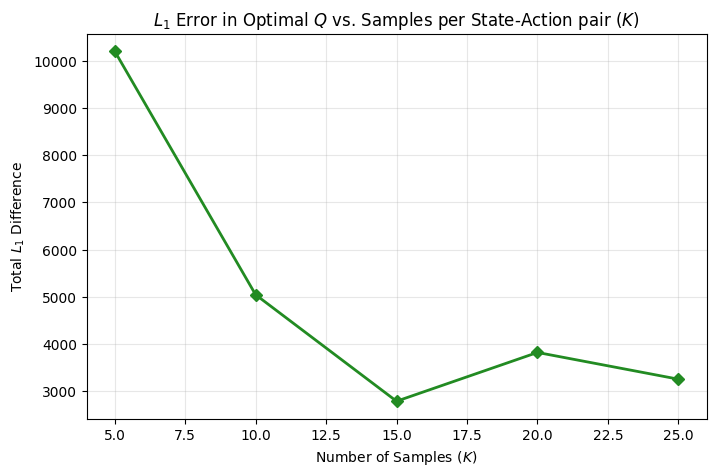

In [19]:
plot_estimation_results(Ks, diffs)

# Question 3(c)

In [ ]:

def run_statistical_estimation_comparison():
    # Parameters
    N = 5
    Ks = [5, 10, 15, 20, 25]
    num_seeds = 5
    gamma = 0.99
    epsilon = 1e-8

    print("Generating exact Q-function for N=5...")
    true_k = kernel(N)
    true_r = reward(N)
    Q_optimal_exact = value_iteration(true_k, true_r, gamma, epsilon)

    
    all_l1_diffs = np.zeros((num_seeds, len(Ks)))

    for seed_idx in range(num_seeds):
        # Set the seed for reproducibility across the 5 trials
        current_seed = seed_idx * 42  # Unique seed for each trial
        np.random.seed(current_seed)
        print(f"\n--- Starting Trial {seed_idx + 1}/{num_seeds} (Seed: {current_seed}) ---")

        for k_idx, K in enumerate(Ks):
            start_time = time.time()
            
            # Estimate Kernel
            hat_kernel = estimate_kernel(N, K)
            
            # Solve using Value Iteration on the estimate
            hat_Q = value_iteration(hat_kernel, true_r, gamma, epsilon)
            
            # Calculate L1 Difference
            l1_diff = np.sum(np.abs(Q_optimal_exact - hat_Q))
            all_l1_diffs[seed_idx, k_idx] = l1_diff
            
            elapsed = time.time() - start_time
            print(f"K={K} | L1 Diff: {l1_diff:.2f} | Time: {elapsed:.2f}s")

    
    mean_l1 = np.mean(all_l1_diffs, axis=0)
    std_l1 = np.std(all_l1_diffs, axis=0)

    return Ks, mean_l1, std_l1


In [21]:
Ks, mean_l1, std_l1 = run_statistical_estimation_comparison()

Generating exact Q-function for N=5...

--- Starting Trial 1/5 (Seed: 0) ---
K=5 | L1 Diff: 6470.87 | Time: 0.16s
K=10 | L1 Diff: 4330.04 | Time: 0.17s
K=15 | L1 Diff: 4294.63 | Time: 0.23s
K=20 | L1 Diff: 2212.74 | Time: 0.24s
K=25 | L1 Diff: 1675.97 | Time: 0.30s

--- Starting Trial 2/5 (Seed: 42) ---
K=5 | L1 Diff: 6282.48 | Time: 0.15s
K=10 | L1 Diff: 3441.54 | Time: 0.18s
K=15 | L1 Diff: 1748.04 | Time: 0.24s
K=20 | L1 Diff: 2318.67 | Time: 0.29s
K=25 | L1 Diff: 1926.57 | Time: 0.32s

--- Starting Trial 3/5 (Seed: 84) ---
K=5 | L1 Diff: 6757.45 | Time: 0.16s
K=10 | L1 Diff: 5454.92 | Time: 0.24s
K=15 | L1 Diff: 2432.77 | Time: 0.24s
K=20 | L1 Diff: 2424.51 | Time: 0.29s
K=25 | L1 Diff: 1945.93 | Time: 0.31s

--- Starting Trial 4/5 (Seed: 126) ---
K=5 | L1 Diff: 7706.20 | Time: 0.13s
K=10 | L1 Diff: 2723.91 | Time: 0.19s
K=15 | L1 Diff: 2814.20 | Time: 0.20s
K=20 | L1 Diff: 2476.70 | Time: 0.25s
K=25 | L1 Diff: 1282.98 | Time: 0.34s

--- Starting Trial 5/5 (Seed: 168) ---
K=5 | L1 

In [22]:
def plot_statistical_results(Ks, mean_vals, std_vals):
    plt.figure(figsize=(10, 6))
    
    # Plot mean with markers
    plt.plot(Ks, mean_vals, color='navy', marker='o', label='Mean $L_1$ Difference', linewidth=2)
    
    # Add shaded region for standard deviation
    plt.fill_between(Ks, mean_vals - std_vals, mean_vals + std_vals, 
                     color='royalblue', alpha=0.2, label='Standard Deviation ($sigma$)')
    
    # Also add error bars for clarity
    plt.errorbar(Ks, mean_vals, yerr=std_vals, fmt='none', ecolor='navy', capsize=5)

    plt.title('Mean $L_1$ Error in Optimal $Q$ with Variance across 5 Random Seeds', fontsize=14)
    plt.xlabel('Number of Samples ($K$) per State-Action pair', fontsize=12)
    plt.ylabel('Total $L_1$ Difference', fontsize=12)
    plt.grid(True, which='both', linestyle='--', alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()

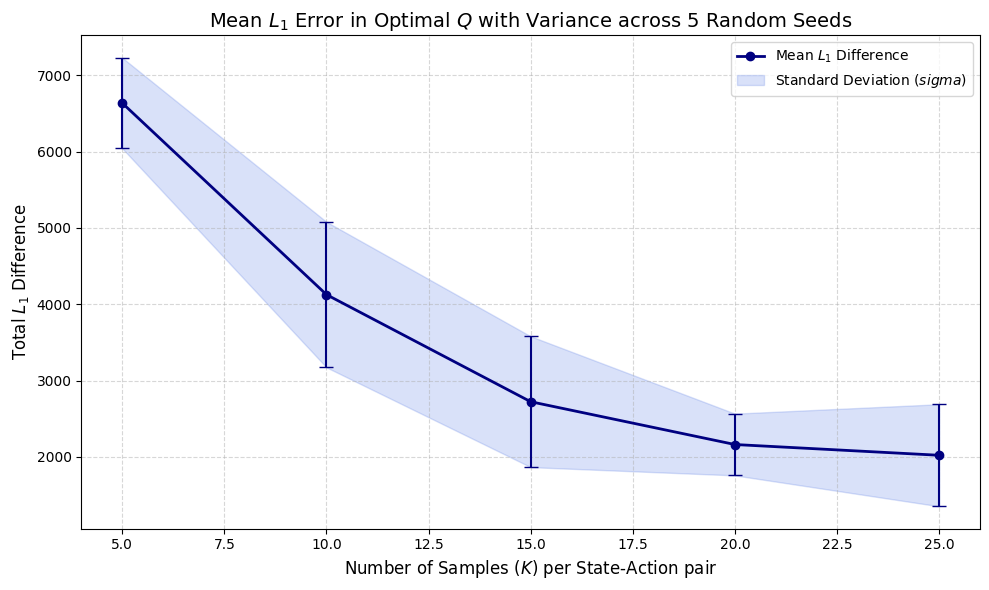

In [23]:
plot_statistical_results(Ks, mean_l1, std_l1)